In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
import numpy as np, sympy as sp
from IPython.display import Image, display, Markdown
sp.init_printing(use_unicode=True)
def show(path):
    p = path[0] if isinstance(path, tuple) else path
    display(Image(filename=p))


# 02. Metric variation

Verify $g^{\mu\nu}=\bar g^{\mu\nu}-\epsilon h^{\mu\nu}+\epsilon^2 h^\mu{}_\rho h^{\rho\nu}+O(\epsilon^3)$ and
$\sqrt{-g}=\sqrt{-\bar g}[1+\tfrac\epsilon2 h+\epsilon^2(\tfrac18 h^2-\tfrac14 h_{\mu\nu}h^{\mu\nu})]$ with a **generic**
symmetric $h$ (ten independent symbols) and then show that the checks detect plausible mistakes.

In [2]:
from desitter_perturbations.symbolic import metric_expansion as me
gbar = me.generic_diagonal_background(); h = me.generic_perturbation()
print("inverse metric residual (should be zero matrix):")
print(me.check_inverse_metric(gbar, h, 2))
print("sqrt(-g) coefficient residuals:", me.check_sqrt_det(gbar, h))

inverse metric residual (should be zero matrix):


Matrix([[0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0], [0, 0, 0, 0]])


sqrt(-g) coefficient residuals: (0, 0)


In [3]:
print("wrong sign at 2nd order detected:", any(e != 0 for e in me.check_inverse_metric(gbar, h, 2, builder=me.inverse_metric_series_wrong_sign)))
d1, d2 = me.check_sqrt_det(gbar, h, formula=me.sqrt_det_series_formula_wrong_factor)
print("factor-of-two error in h_mn h^mn term detected:", d1 == 0 and d2 != 0)
print("residual of the wrong determinant formula:", d2)

wrong sign at 2nd order detected: True


factor-of-two error in h_mn h^mn term detected: True
residual of the wrong determinant formula: h33**2/(4*b3**2) + h23**2/(2*b2*b3) + h22**2/(4*b2**2) + h13**2/(2*b1*b3) + h12**2/(2*b1*b2) + h11**2/(4*b1**2) - h03**2/(2*b0*b3) - h02**2/(2*b0*b2) - h01**2/(2*b0*b1) + h00**2/(4*b0**2)


Numerical order check: truncating the series one order earlier must degrade the error by exactly one power of $\epsilon$.

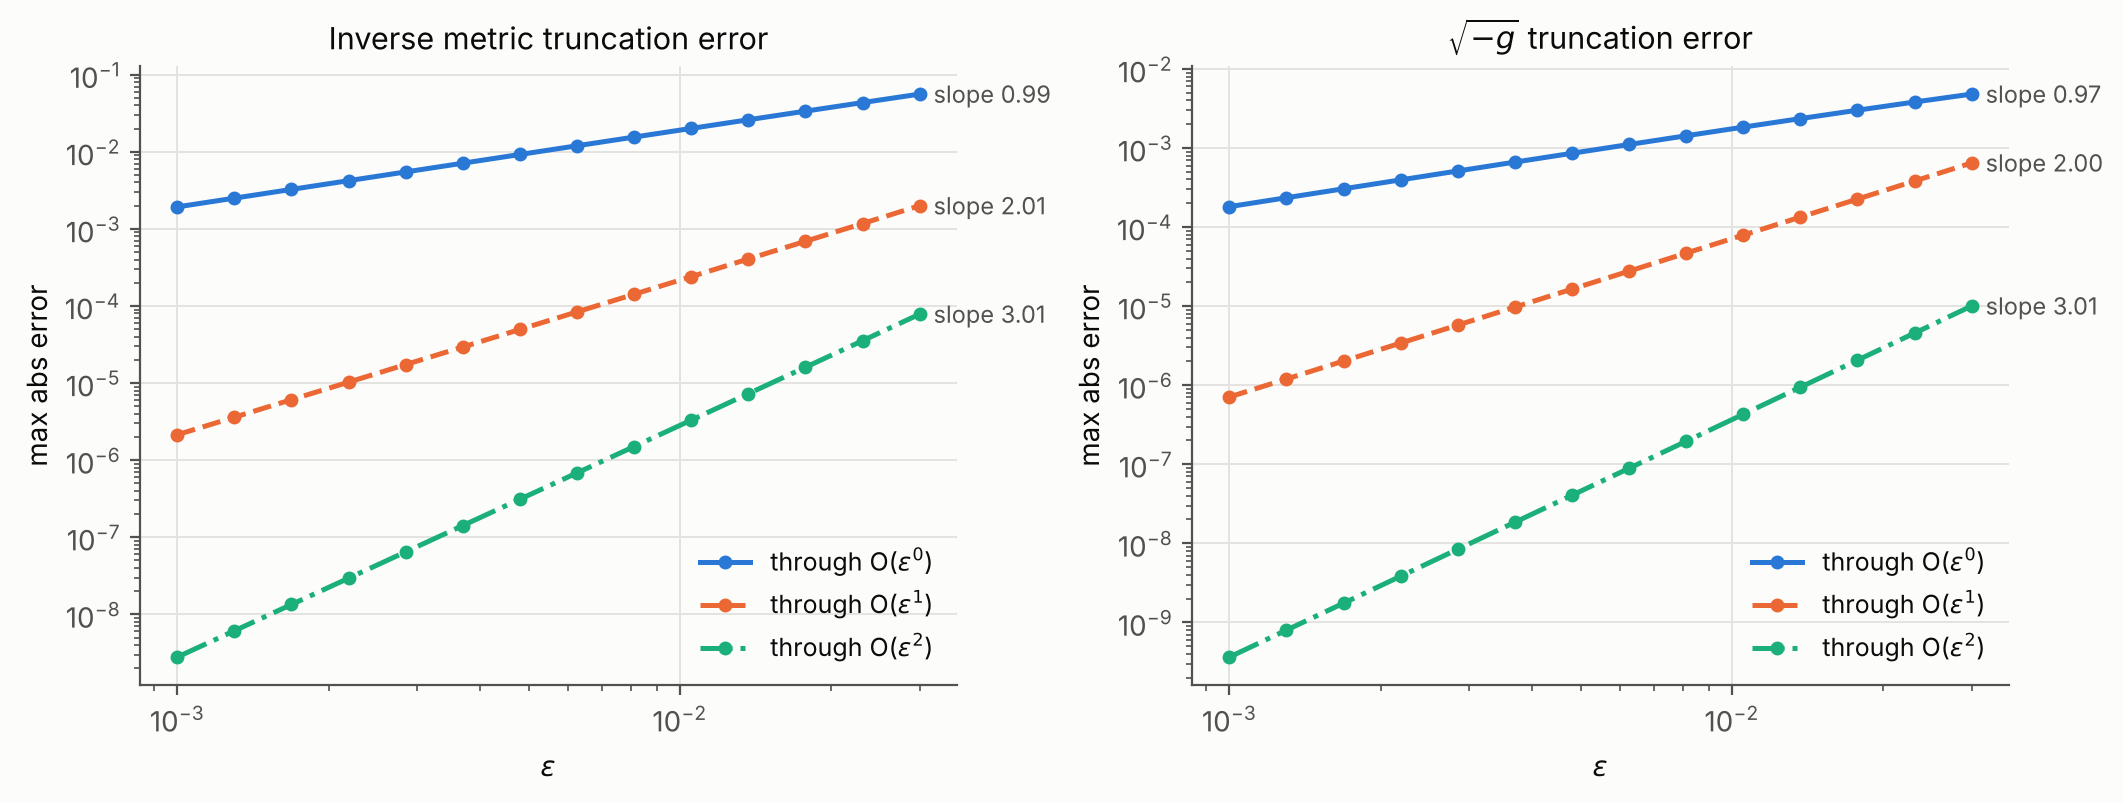

{'inv0': 0.992, 'inv1': 2.01, 'inv2': 3.01, 'det0': 0.969, 'det1': 2.004, 'det2': 3.006}


In [4]:
from desitter_perturbations.visualization import geometry_plots as gp
path, slopes = gp.plot_expansion_errors()
show(path); print({k: round(v, 3) for k, v in slopes.items()})